# Air Astana Group — synthetic aircraft-availability scenarios
**NOT observed Air Astana data.** The official report supplies contextual aggregate facts, not these 1,500 records.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency

# Run from repository root (same directory as data_raw.csv)
raw = pd.read_csv('data_raw.csv')
print('Raw dataset:', raw.shape)
print('Raw missing cells:', int(raw.isna().sum().sum()))


Raw dataset: (1500, 14)
Raw missing cells: 4


In [2]:
df=raw.copy()
df["season"]=df["season"].str.strip().str.lower()
df["planned_buffer_hours"]=df["planned_buffer_hours"].mask(df["planned_buffer_hours"]<0)
for col in ["planned_buffer_hours","estimated_engine_work_hours"]:
    df[col]=df[col].fillna(df[col].median())
assert len(df)>=1000 and len(df.columns)>=10
assert df["scenario_source"].eq("SYNTHETIC").all()
assert df.isna().sum().sum()==0
expected=pd.read_csv("data_clean.csv")
pd.testing.assert_frame_equal(df,expected,check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-9)
print("Cleaning reproduced exactly; raw missing values:",raw.isna().sum().sum())
print("Raw negative buffer values:",(raw["planned_buffer_hours"]<0).sum())
print("Clean shape:",df.shape)


Cleaning reproduced exactly; raw missing values: 4
Raw negative buffer values: 3
Clean shape: (1500, 14)


In [3]:
peak=df.loc[df.season=="peak","modeled_downtime_hours"]
other=df.loc[df.season=="off_peak","modeled_downtime_hours"]
t1=ttest_ind(peak,other,equal_var=False)
print("H01 peak vs offpeak:",peak.mean(),other.mean(),"p=",t1.pvalue)

H01 peak vs offpeak: 11.265346534653466 6.477386934673367 p= 9.519164266248058e-33


In [4]:
spare=df.loc[df.spare_engine_available==1,"modeled_downtime_hours"]
no_spare=df.loc[df.spare_engine_available==0,"modeled_downtime_hours"]
t2=ttest_ind(spare,no_spare,equal_var=False)
print("H02 spare vs no spare:",spare.mean(),no_spare.mean(),"p=",t2.pvalue)

H02 spare vs no spare: 5.278207109737249 10.221570926143025 p= 1.4074959425005475e-44


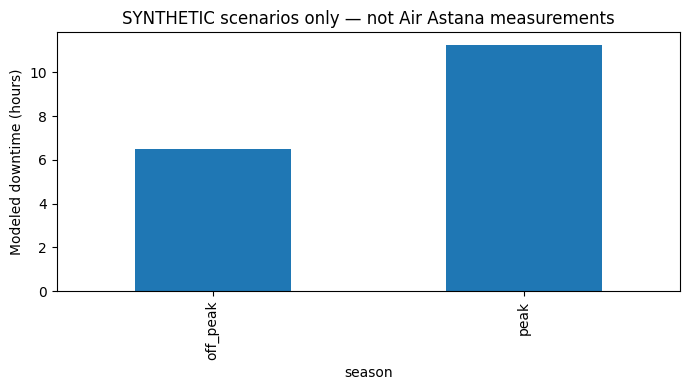

In [5]:
fig,ax=plt.subplots(figsize=(7,4))
df.groupby("season")["modeled_downtime_hours"].mean().plot(kind="bar",ax=ax)
ax.set_ylabel("Modeled downtime (hours)")
ax.set_title("SYNTHETIC scenarios only — not Air Astana measurements")
plt.tight_layout();plt.show()

## Interpretation
These p-values reflect the *assumed simulation-generating process*. They do **not** demonstrate actual Air Astana downtime, engine spare availability, or causal effects. The annual report establishes the existence of unscheduled engine removals and capacity constraints at group level only.

## Robustness check: binary downtime threshold
This is an additional *synthetic-scenario* association test, not evidence about Air Astana operations.

In [6]:
from scipy.stats import chi2_contingency
contingency = pd.crosstab(df["season"], df["downtime_15h_or_more"])
chi2, p_value, dof, expected = chi2_contingency(contingency)
print(contingency)
print("Chi-square p-value (synthetic scenarios):", p_value)


downtime_15h_or_more    0    1
season                        
off_peak              856  139
peak                  352  153
Chi-square p-value (synthetic scenarios): 7.531239150346297e-14


## Source discipline
Only Air Astana Group Integrated Report 2025 has been independently verified. The report supplies 14 summer peak unscheduled engine removals, 22 year-to-date and up to 13 aircraft grounded at peak. The simulated scenarios are **not calibrated to those event counts**, and the report does not provide a baseline downtime-hours distribution. At least two more independently verifiable public sources are needed for the project brief.